# TTE map: view tiles made with the Python workflow

Shows the taiga-tundra ecotone (TTE) forest structure pattern classes made by `lib/tte_map.py`
(the Python port of the GEE map, Montesano et al. 2020 ERL), in the palette of the original GEE
scripts (`tte_class_pal` in `TTE_map_publish.js`), next to the published GEE map
`TTE_DATA_v201902v2` for the same tiles.

**How to use it.** Put the places you want to see in `SITES` (step 1), as a lon/lat box, a point,
or a list of tile numbers, then run all cells. Any tile that has not been made yet is run here
(about a minute per 1-degree tile) and saved, so the next time it just loads.

The first places are the eastern Seward Peninsula, the Noatak River and the eastern Brooks Range
(Alaska), northern Scandinavia (Finnmark / Utsjoki) and Khatanga (Taymyr, with Ary-Mas). Nothing
below depends on them.

**Keep in mind for North America:** the GEE map used a calibrated 2 m tree cover (`cal_2m_tcc`) there,
which can't be read outside GEE. The Python tiles here use Hansen 2010, so the two maps differ in
North America because of the tree cover input. In Eurasia both use Hansen and agree on 90-94% of pixels
(`tte/validation.md`).

## 0. Setup

In [1]:
import os, sys, warnings

# PROJ database of the Hub conda env (needed for the polar LAEA grid when run from a terminal)
if os.path.isdir('/srv/conda/envs/notebook/share/proj'):
    os.environ.setdefault('PROJ_DATA', '/srv/conda/envs/notebook/share/proj')

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.crs import CRS
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.warp import reproject, transform_bounds
from pyproj import Transformer
from shapely.geometry import box, Point
from shapely.ops import transform as shp_transform
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap
from matplotlib.patches import Patch

warnings.filterwarnings('ignore', message='.*geographic CRS.*')

REPO = os.path.expanduser('~/code/tte')
sys.path.insert(0, os.path.join(REPO, 'lib'))
import tte_map as tm


def mounted_or(mount_path, s3_path):
    # Hub has the buckets mounted under /home/jovyan; elsewhere fall back to s3
    return mount_path if os.path.exists(mount_path) else s3_path

TILES_GPKG  = mounted_or('/home/jovyan/my-public-bucket/databank/tte_tiles.gpkg', tm.TILES_GPKG)
DOMAIN_PATH = mounted_or('/home/jovyan/my-public-bucket/tte/static/tte_domain_v201902v2_hubmount.vrt', tm.DOMAIN_VRT)
GEE_TINDEX  = mounted_or('/home/jovyan/my-public-bucket/DPS_tile_lists/TTE/download_gee_tiles_v1/'
                         'tte_montesano_2010_30m/TTE_tindex_master.csv', None)
print('tiles :', TILES_GPKG)
print('domain:', DOMAIN_PATH)
print('GEE   :', GEE_TINDEX)

tiles : /home/jovyan/my-public-bucket/databank/tte_tiles.gpkg
domain: /home/jovyan/my-public-bucket/tte/static/tte_domain_v201902v2_hubmount.vrt
GEE   : /home/jovyan/my-public-bucket/DPS_tile_lists/TTE/download_gee_tiles_v1/tte_montesano_2010_30m/TTE_tindex_master.csv


## 1. Settings: which places and which tree cover

Each entry in `SITES` is one map. Give it one of:

* `bbox=(lon_min, lat_min, lon_max, lat_max)`: every 1-degree tile that overlaps the box
* `point=(lon, lat)`: the tile that holds the point (add `buffer_deg=0.5` to take neighbours too)
* `tile_nums=[...]`: those tiles from `tte_tiles.gpkg`

`MAX_TILES` stops a big box from starting dozens of runs by mistake.

To look at maps made from another tree cover, set `TCC_LABEL` to that run's output label
(files are named `tte_<TCC_LABEL>_<tile_num>.tif`), `OUT_DIR` to where they are, and `RUN_KW` to the
`tm.run_tile` arguments that make them (for example
`dict(tcc_source='path', tcc_paths=['s3://.../my_tcc.vrt'], tcc_resampling='average', out_name='mytcc')`).

In [2]:
SITES = {
    'Eastern Seward Peninsula': dict(bbox=(-163, 64, -161, 66)),
    'Noatak River':             dict(bbox=(-163, 67, -159, 68)),
    'Eastern Brooks Range':     dict(bbox=(-146, 67, -144, 69)),
    'Northern Scandinavia':     dict(bbox=(25, 69, 27, 71)),        # Finnmark / Utsjoki, mountain birch treeline
    'Khatanga':                 dict(bbox=(101, 71, 103, 73)),      # Khatanga and Ary-Mas, northernmost larch forest
}

TCC_LABEL   = 'hansen2010'                                    # output files: tte_<TCC_LABEL>_NNNNNNN.tif
RUN_KW      = dict(tcc_source='hansen', tcc_year=2010)        # how to make a missing tile
OUT_DIR     = os.path.expanduser('~/my-private-bucket/tte/tiles_hansen2010')   # new tiles go here
SEARCH_DIRS = [OUT_DIR, os.path.expanduser('~/my-private-bucket/tte/test_python_vs_gee')]
RUN_MISSING = True      # make tiles that are not found in SEARCH_DIRS
SHOW_GEE    = True      # show the published GEE map (TTE_DATA_v201902v2) next to the Python map
DISPLAY_RES = 30        # metres; 30 is the native resolution, 60-90 draws faster for big areas
MAX_TILES   = 8         # per site

## 2. Helpers

Class colors and names come from `tte_map.py`, which copies the GEE palette
(`#5255a3 #1796a3 #fdbf6f #ff7f00` sparse, `#ffffbf #d9ef8b #91cf60 #1a9850` open,
`#c4c4c4` intermediate & closed, red and blue for the dry and wet non-forest edge).
Domain pixels that are not classified (tree cover 0 with no change nearby) are drawn in the GEE
domain gray `#787878`.

Each site is drawn on its own equal-area grid centred on the site (north up), so tiles from any
longitude look right. Both maps are resampled to that grid with nearest neighbour, so class
values don't change.

In [3]:
DOMAIN_COLOR = '#787878'
CLASS_CMAP = ListedColormap(tm.CLASS_COLORS)
CLASS_NORM = BoundaryNorm(np.arange(0.5, 12.5), CLASS_CMAP.N)
# other GEE palettes (TTE_map.js / TTE_map_publish.js), for the optional plots at the end
TCC_CMAP   = LinearSegmentedColormap.from_list('tcc', ['#8c510a','#d9f0a3','#addd8e','#78c679','#41ab5d','#238443','#005a32'])
ABR_CMAP   = LinearSegmentedColormap.from_list('abr', ['#d7191c','#fdae61','#ffffbf','#abdda4','#2b83ba'][::-1])
ZONE_CMAP  = ListedColormap(['#fc8d59', '#63d062', '#058d16'])

tiles = gpd.read_file(TILES_GPKG).to_crs(4326)[['tile_num', 'geometry']]
gee_index = pd.read_csv(GEE_TINDEX) if GEE_TINDEX else None


def site_tiles(site):
    # tiles of tte_tiles.gpkg for one SITES entry
    if 'tile_nums' in site:
        sel = tiles[tiles.tile_num.isin([int(t) for t in site['tile_nums']])]
    elif 'bbox' in site:
        g = box(*site['bbox'])
        sel = tiles[tiles.intersection(g).area > 0.01]      # ignore slivers along tile edges
    elif 'point' in site:
        g = Point(site['point']).buffer(site.get('buffer_deg', 0) or 1e-6)
        sel = tiles[tiles.intersects(g)]
    else:
        raise ValueError(f'site needs bbox, point or tile_nums: {site}')
    sel = sel.sort_values('tile_num')
    if len(sel) > MAX_TILES:
        print(f'  {len(sel)} tiles, keeping the first {MAX_TILES} (raise MAX_TILES to see all)')
        sel = sel.iloc[:MAX_TILES]
    return sel


def python_tile(tile_num):
    # path of an existing Python tile, or run it (None if it is outside the TTE domain)
    name = f'tte_{TCC_LABEL}_{int(tile_num):07}.tif'
    for d in SEARCH_DIRS:
        if os.path.exists(os.path.join(d, name)):
            return os.path.join(d, name)
    if not RUN_MISSING:
        return None
    return tm.run_tile(int(tile_num), OUT_DIR, domain_path=DOMAIN_PATH, tiles_gpkg=TILES_GPKG, **RUN_KW)


def gee_tile(tile_num):
    if gee_index is None:
        return None
    r = gee_index[gee_index.tile_num == int(tile_num)]
    if len(r) == 0:
        return None
    p = r.local_path.values[-1].replace('/projects/', '/home/jovyan/')
    return p if os.path.exists(p) else r.s3_path.values[-1]


def site_grid(sel, res=DISPLAY_RES):
    # equal-area grid centred on the tiles (km from the centre on the axes)
    geom = sel.geometry.union_all() if hasattr(sel.geometry, 'union_all') else sel.geometry.unary_union
    lon0, lat0 = geom.centroid.coords[0]
    crs = CRS.from_proj4(f'+proj=laea +lat_0={lat0:.4f} +lon_0={lon0:.4f} +datum=WGS84 +units=m +no_defs')
    xmin, ymin, xmax, ymax = transform_bounds('EPSG:4326', crs, *sel.total_bounds, densify_pts=51)
    shape = (int(np.ceil((ymax - ymin) / res)), int(np.ceil((xmax - xmin) / res)))
    return dict(crs=crs, transform=from_origin(xmin, ymax, res, res), shape=shape, res=res,
                extent=[xmin / 1e3, (xmin + shape[1] * res) / 1e3, (ymax - shape[0] * res) / 1e3, ymax / 1e3],
                center=(lon0, lat0))


def mosaic(paths, grid, bands=tm.BAND_NAMES):
    # nearest-neighbour mosaic of TTE tiles (Python or GEE) onto the site grid; NaN = no data
    out = {b: np.full(grid['shape'], np.nan, np.float32) for b in bands}
    for p in paths:
        if p is None:
            continue
        with rasterio.Env(**tm.GDAL_ENV), rasterio.open(tm.as_gdal_path(p)) as src:
            names = list(src.descriptions)
            for b in bands:
                tmp = np.full(grid['shape'], np.nan, np.float32)
                reproject(rasterio.band(src, names.index(b) + 1), tmp, src_nodata=src.nodata,
                          dst_transform=grid['transform'], dst_crs=grid['crs'], dst_nodata=np.nan,
                          resampling=Resampling.nearest)
                tmp[~np.isfinite(tmp)] = np.nan          # GEE tiles use -inf as nodata
                fill = np.isnan(out[b]) & ~np.isnan(tmp)
                out[b][fill] = tmp[fill]
    return out


def draw_tile_outlines(ax, sel, grid):
    tr = Transformer.from_crs('EPSG:4326', grid['crs'], always_xy=True)
    for _, r in sel.iterrows():
        g = shp_transform(lambda x, y: tuple(np.array(v) / 1e3 for v in tr.transform(x, y)),
                          r.geometry.segmentize(0.05))
        ax.plot(*g.exterior.xy, color='k', lw=0.6)
        c = g.centroid
        ax.text(c.x, c.y, str(r.tile_num), ha='center', va='center', fontsize=8, clip_on=True,
                path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])


def draw_classes(ax, m, grid, title):
    dom = np.where(np.isfinite(m['tte_domain']), 1.0, np.nan)
    ax.imshow(dom, extent=grid['extent'], cmap=ListedColormap([DOMAIN_COLOR]), interpolation='nearest')
    ax.imshow(m['tte_classification'], extent=grid['extent'], cmap=CLASS_CMAP, norm=CLASS_NORM,
              interpolation='nearest')
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('km');  ax.set_ylabel('km')


def class_legend(fig):
    handles = [Patch(facecolor=c, edgecolor='0.5', lw=0.3, label=f'{k}  {tm.CLASS_NAMES[k]}')
               for k, c in zip(range(1, 12), tm.CLASS_COLORS)]
    handles.append(Patch(facecolor=DOMAIN_COLOR, label='TTE domain, not classified'))
    fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=9, frameon=False,
               bbox_to_anchor=(0.5, -0.01))


def zoom_to(axes, grid, lon, lat, half_km):
    x, y = Transformer.from_crs('EPSG:4326', grid['crs'], always_xy=True).transform(lon, lat)
    for ax in np.atleast_1d(axes):
        ax.set_xlim(x / 1e3 - half_km, x / 1e3 + half_km)
        ax.set_ylim(y / 1e3 - half_km, y / 1e3 + half_km)


def fig_size(grid, ncols, zoom, figwidth, max_panel_h=12, extra_h=0.0):
    # panel size from the map's aspect, capped so tall sites don't make huge figures
    h, w = grid['shape']
    aspect = 1 if zoom is not None else h / w
    pw = figwidth / ncols
    if pw * aspect > max_panel_h:
        pw = max_panel_h / aspect
    return pw * ncols, pw * aspect + extra_h


def show_site(name, zoom=None, figwidth=15):
    # Python (left) and GEE (right) classification for one site; zoom=(lon, lat, half_width_km)
    d = DATA[name]
    grid = d['grid']
    maps = [(d['py'], f'Python, {TCC_LABEL}')]
    if d.get('gee') is not None:
        maps.append((d['gee'], 'GEE TTE_DATA_v201902v2'))
    W, H = fig_size(grid, len(maps), zoom, figwidth, extra_h=2.2)   # 2.2 in for title + legend
    fig, axes = plt.subplots(1, len(maps), figsize=(W, H), sharex=True, sharey=True, squeeze=False)
    for ax, (m, title) in zip(axes[0], maps):
        draw_classes(ax, m, grid, title)
        draw_tile_outlines(ax, d['tiles'], grid)
    if zoom is not None:
        zoom_to(axes[0], grid, *zoom)
    lon0, lat0 = grid['center']
    where = f'zoom on {zoom[0]:.2f}, {zoom[1]:.2f}' if zoom else f'centre {lon0:.2f}, {lat0:.2f}'
    fig.suptitle(f'{name}  ({where})', fontsize=13)
    class_legend(fig)
    fig.tight_layout(rect=(0, 1.6 / H, 1, 1 - 0.45 / H))
    plt.show()


def class_table(name):
    # share of classified pixels in each class (%), and classified area (km2)
    d = DATA[name]
    px_km2 = d['grid']['res'] ** 2 / 1e6
    cols = {}
    for label, m in [('Python', d['py']), ('GEE', d.get('gee'))]:
        if m is None:
            continue
        c = m['tte_classification']
        n = np.bincount(c[np.isfinite(c)].astype(int), minlength=12)[1:12]
        cols[label + ' %'] = 100 * n / max(n.sum(), 1)
        cols[label + ' km2'] = n * px_km2
    df = pd.DataFrame(cols, index=[f'{k} {tm.CLASS_NAMES[k]}' for k in range(1, 12)])
    df.loc['all classified'] = df.sum()
    return df.round(1)

## 3. Find the tiles for each site and make or load them

New tiles are written to `OUT_DIR`. A tile outside the TTE domain gives no file (it says
"outside the TTE domain") and is skipped.

In [4]:
DATA = {}
for name, site in SITES.items():
    print(name)
    sel = site_tiles(site)
    py_paths = {t: python_tile(t) for t in sel.tile_num}
    gee_paths = {t: gee_tile(t) for t in sel.tile_num} if SHOW_GEE else {}
    DATA[name] = dict(tiles=sel, py_paths=py_paths, gee_paths=gee_paths)
    for t in sel.tile_num:
        print(f'  {t}: python {os.path.basename(py_paths[t] or "-")}   GEE {"yes" if gee_paths.get(t) else "-"}')

Eastern Seward Peninsula


  3251: python tte_hansen2010_0003251.tif   GEE yes
  3252: python tte_hansen2010_0003252.tif   GEE yes
  3571: python tte_hansen2010_0003571.tif   GEE yes
  3572: python tte_hansen2010_0003572.tif   GEE yes
Noatak River


  4207: python tte_hansen2010_0004207.tif   GEE yes
  4208: python tte_hansen2010_0004208.tif   GEE yes
  4209: python tte_hansen2010_0004209.tif   GEE yes
  4210: python tte_hansen2010_0004210.tif   GEE yes
Eastern Brooks Range


  4224: python tte_hansen2010_0004224.tif   GEE yes
  4225: python tte_hansen2010_0004225.tif   GEE yes
  4528: python tte_hansen2010_0004528.tif   GEE yes
  4529: python tte_hansen2010_0004529.tif   GEE yes
Northern Scandinavia


  525: python tte_hansen2010_0000525.tif   GEE yes
  526: python tte_hansen2010_0000526.tif   GEE yes
  4949: python tte_hansen2010_0004949.tif   GEE yes
  4950: python tte_hansen2010_0004950.tif   GEE yes
Khatanga


  803: python tte_hansen2010_0000803.tif   GEE yes
  804: python tte_hansen2010_0000804.tif   GEE yes
  995: python tte_hansen2010_0000995.tif   GEE yes
  996: python tte_hansen2010_0000996.tif   GEE yes


In [5]:
for name, d in DATA.items():
    d['grid'] = site_grid(d['tiles'])
    d['py'] = mosaic(d['py_paths'].values(), d['grid'])
    d['gee'] = mosaic(d['gee_paths'].values(), d['grid']) if SHOW_GEE and any(d['gee_paths'].values()) else None
    print(f"{name}: grid {d['grid']['shape']} at {DISPLAY_RES} m")

Eastern Seward Peninsula: grid (7445, 3263) at 30 m


Noatak River: grid (3763, 5815) at 30 m


Eastern Brooks Range: grid (7447, 2908) at 30 m


Northern Scandinavia: grid (7448, 2668) at 30 m


Khatanga: grid (7449, 2424) at 30 m


## 4. Maps

One figure per site, Python map on the left and the published GEE map on the right, with
1-degree tile outlines and tile numbers.

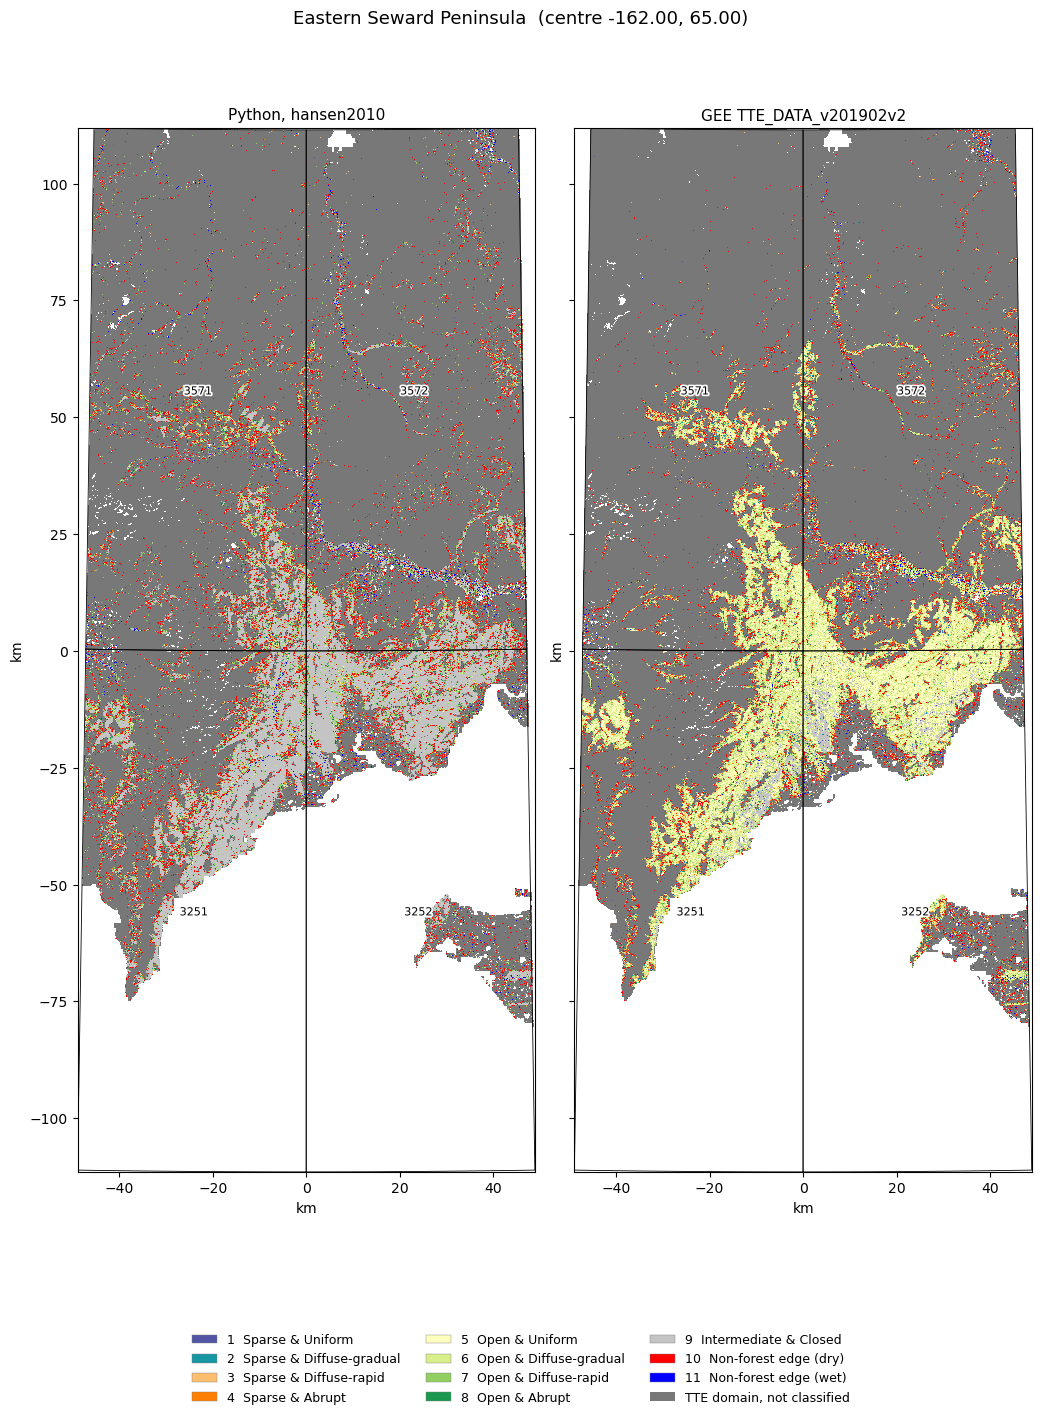

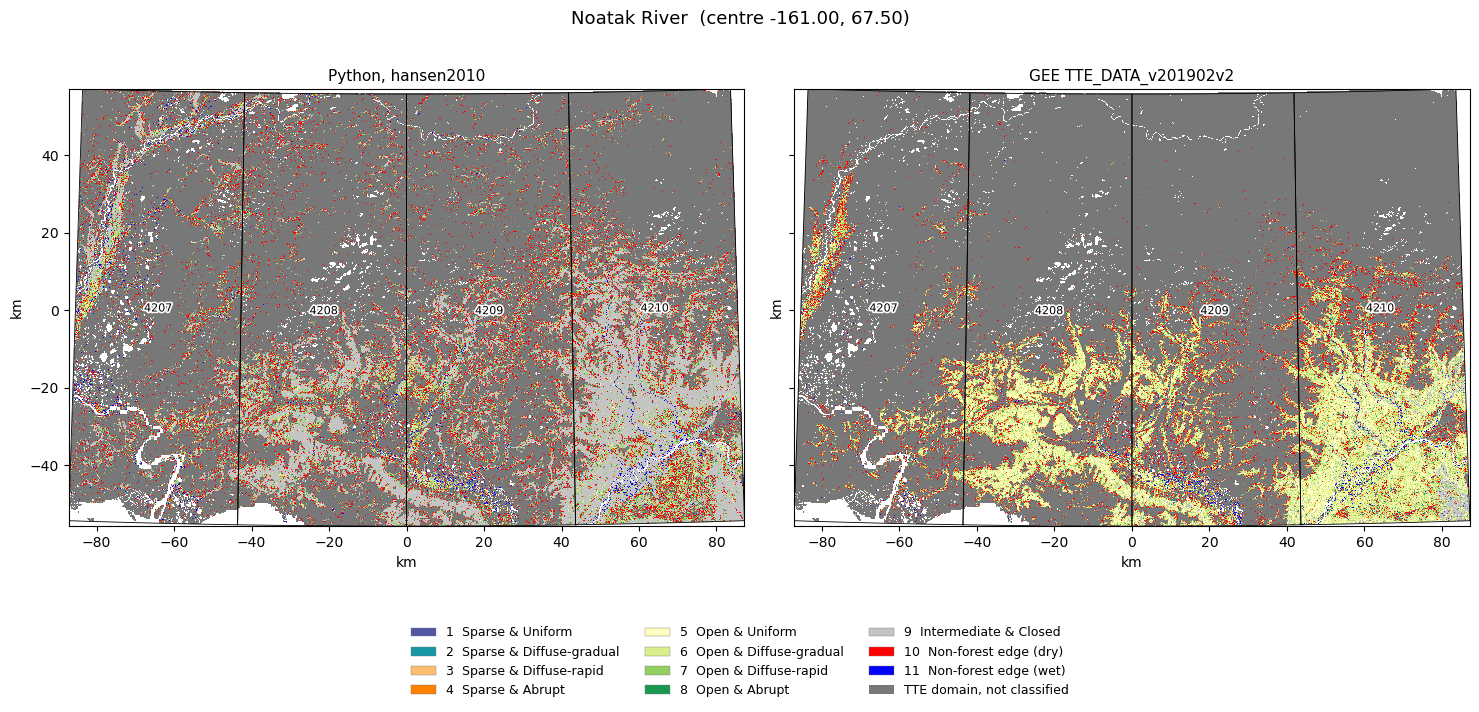

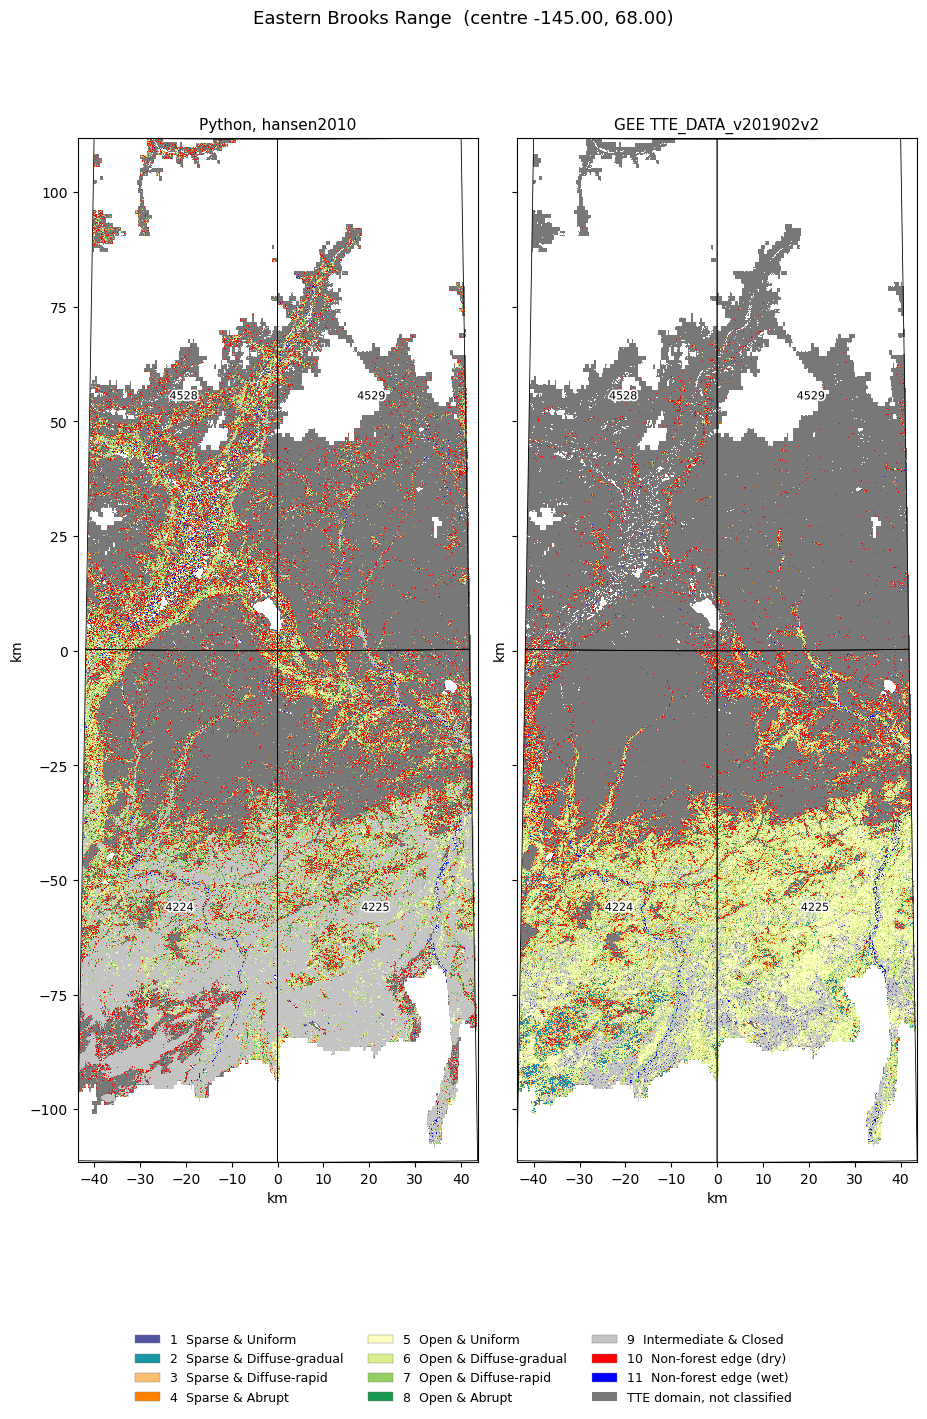

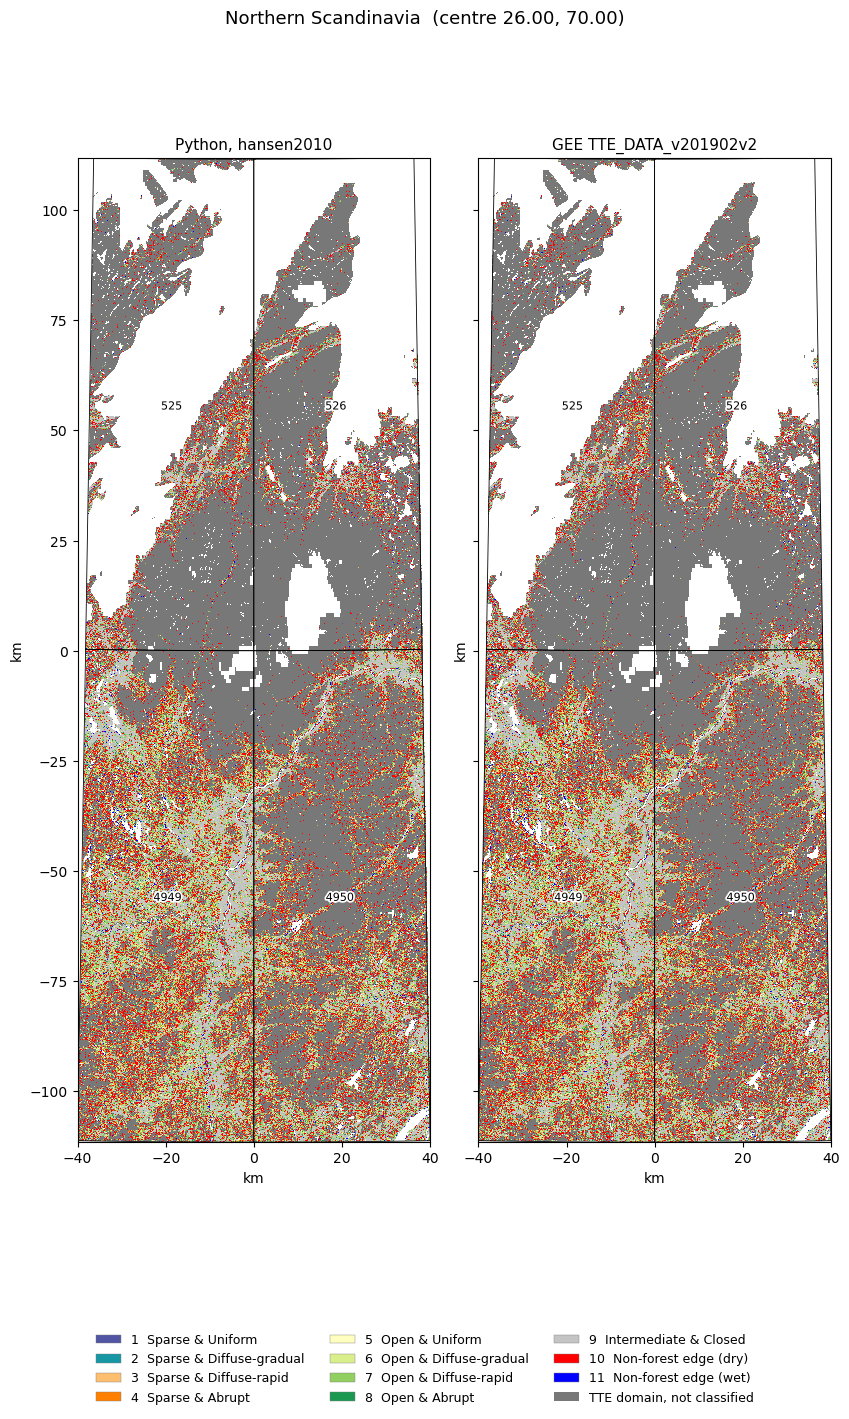

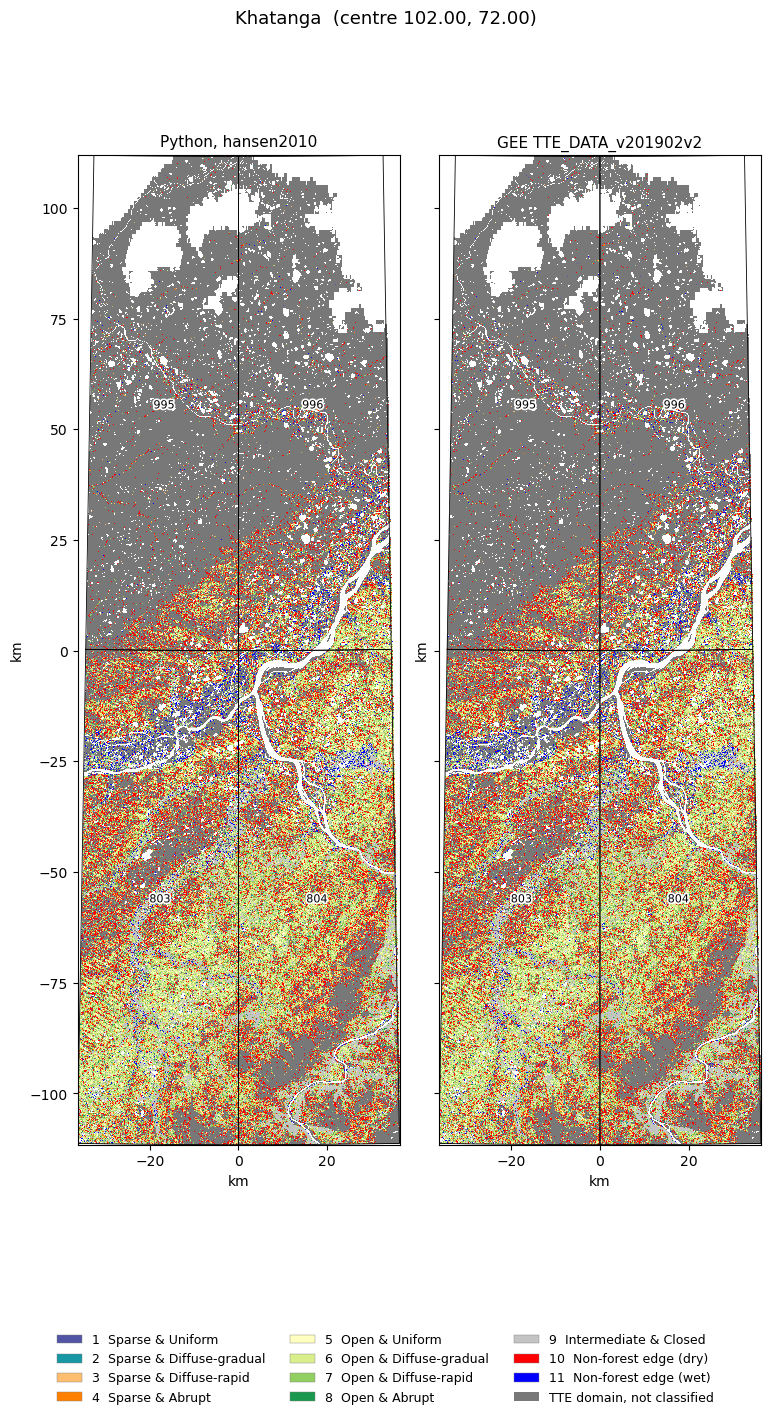

In [6]:
for name in DATA:
    show_site(name)

## 5. Class composition

Share of classified pixels in each class, and area in km², for each site. Areas are from the
site's equal-area grid.

In [7]:
for name in DATA:
    print(name)
    display(class_table(name))

Eastern Seward Peninsula


,Python %,Python km2,GEE %,GEE km2
1 Sparse & Uniform,0.2,5.4,1.6,51.1
2 Sparse & Diffuse-gradual,0.1,4.6,2.1,65.2
3 Sparse & Diffuse-rapid,1.8,56.7,7.5,235.3
4 Sparse & Abrupt,2.0,61.5,3.4,107.7
5 Open & Uniform,0.9,26.3,28.3,884.0
6 Open & Diffuse-gradual,3.5,108.2,27.6,862.9
7 Open & Diffuse-rapid,12.3,379.2,8.7,271.7
8 Open & Abrupt,2.3,72.1,0.1,3.9
9 Intermediate & Closed,52.6,1628.0,4.8,150.9
10 Non-forest edge (dry),22.7,701.2,14.9,465.5


Noatak River


,Python %,Python km2,GEE %,GEE km2
1 Sparse & Uniform,0.2,9.7,1.6,70.2
2 Sparse & Diffuse-gradual,0.2,12.4,2.1,91.8
3 Sparse & Diffuse-rapid,2.3,127.2,8.4,365.9
4 Sparse & Abrupt,2.1,116.7,4.6,199.3
5 Open & Uniform,0.9,51.9,22.9,1001.4
6 Open & Diffuse-gradual,4.5,253.4,26.5,1159.3
7 Open & Diffuse-rapid,13.3,743.4,11.7,510.7
8 Open & Abrupt,2.6,146.3,0.3,11.9
9 Intermediate & Closed,49.1,2736.3,4.0,173.1
10 Non-forest edge (dry),22.8,1272.7,16.7,730.1


Eastern Brooks Range


,Python %,Python km2,GEE %,GEE km2
1 Sparse & Uniform,0.4,25.3,2.8,146.7
2 Sparse & Diffuse-gradual,0.7,45.7,4.1,212.3
3 Sparse & Diffuse-rapid,4.0,258.7,7.5,390.8
4 Sparse & Abrupt,3.5,225.2,3.7,191.2
5 Open & Uniform,3.3,214.2,20.9,1089.8
6 Open & Diffuse-gradual,10.7,695.0,25.8,1350.7
7 Open & Diffuse-rapid,13.8,894.1,8.2,426.0
8 Open & Abrupt,1.9,121.2,0.4,18.3
9 Intermediate & Closed,43.1,2791.6,15.3,797.4
10 Non-forest edge (dry),17.7,1147.3,11.0,576.6


Northern Scandinavia


,Python %,Python km2,GEE %,GEE km2
1 Sparse & Uniform,0.3,16.3,0.3,18.6
2 Sparse & Diffuse-gradual,0.7,40.2,0.7,39.7
3 Sparse & Diffuse-rapid,4.5,252.4,4.5,247.6
4 Sparse & Abrupt,3.9,214.5,4.0,220.6
5 Open & Uniform,1.6,86.8,1.6,89.1
6 Open & Diffuse-gradual,8.8,486.7,8.7,486.1
7 Open & Diffuse-rapid,19.2,1068.8,19.2,1066.9
8 Open & Abrupt,3.2,175.4,3.2,177.4
9 Intermediate & Closed,28.1,1563.4,28.0,1558.1
10 Non-forest edge (dry),28.7,1596.7,28.7,1598.6


Khatanga


,Python %,Python km2,GEE %,GEE km2
1 Sparse & Uniform,0.4,29.3,0.5,30.6
2 Sparse & Diffuse-gradual,1.2,80.2,1.2,78.1
3 Sparse & Diffuse-rapid,7.5,492.0,7.5,490.6
4 Sparse & Abrupt,5.7,376.2,5.8,378.2
5 Open & Uniform,6.2,408.2,6.3,413.1
6 Open & Diffuse-gradual,18.7,1227.3,18.6,1223.1
7 Open & Diffuse-rapid,20.8,1365.2,20.7,1360.5
8 Open & Abrupt,2.0,129.4,2.0,131.7
9 Intermediate & Closed,12.2,798.2,12.1,794.4
10 Non-forest edge (dry),22.1,1447.2,22.2,1456.2


## 6. Zoom in

`show_site(name, zoom=(lon, lat, half_width_km))` shows a close-up at full resolution.
Change the places in this cell to look anywhere in the sites above.

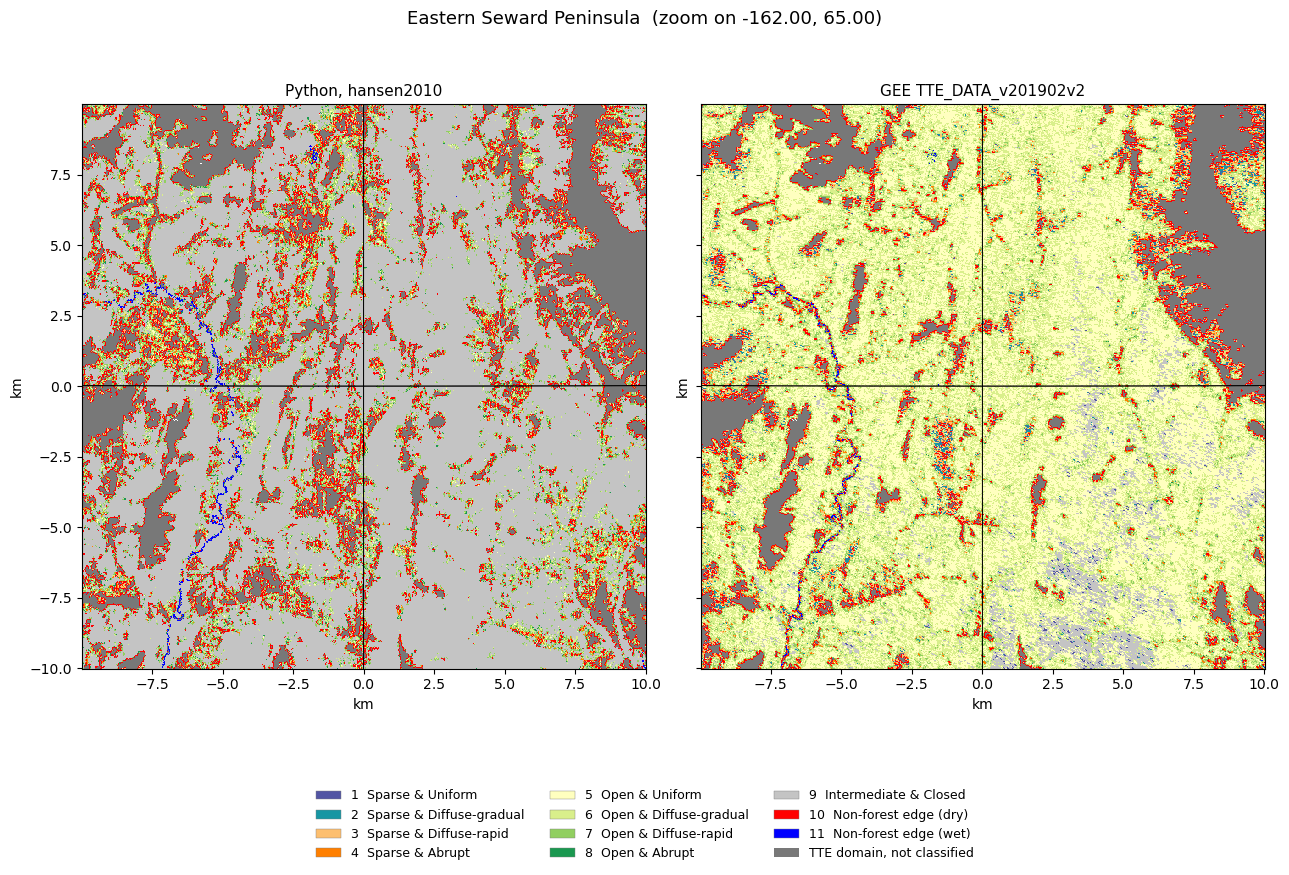

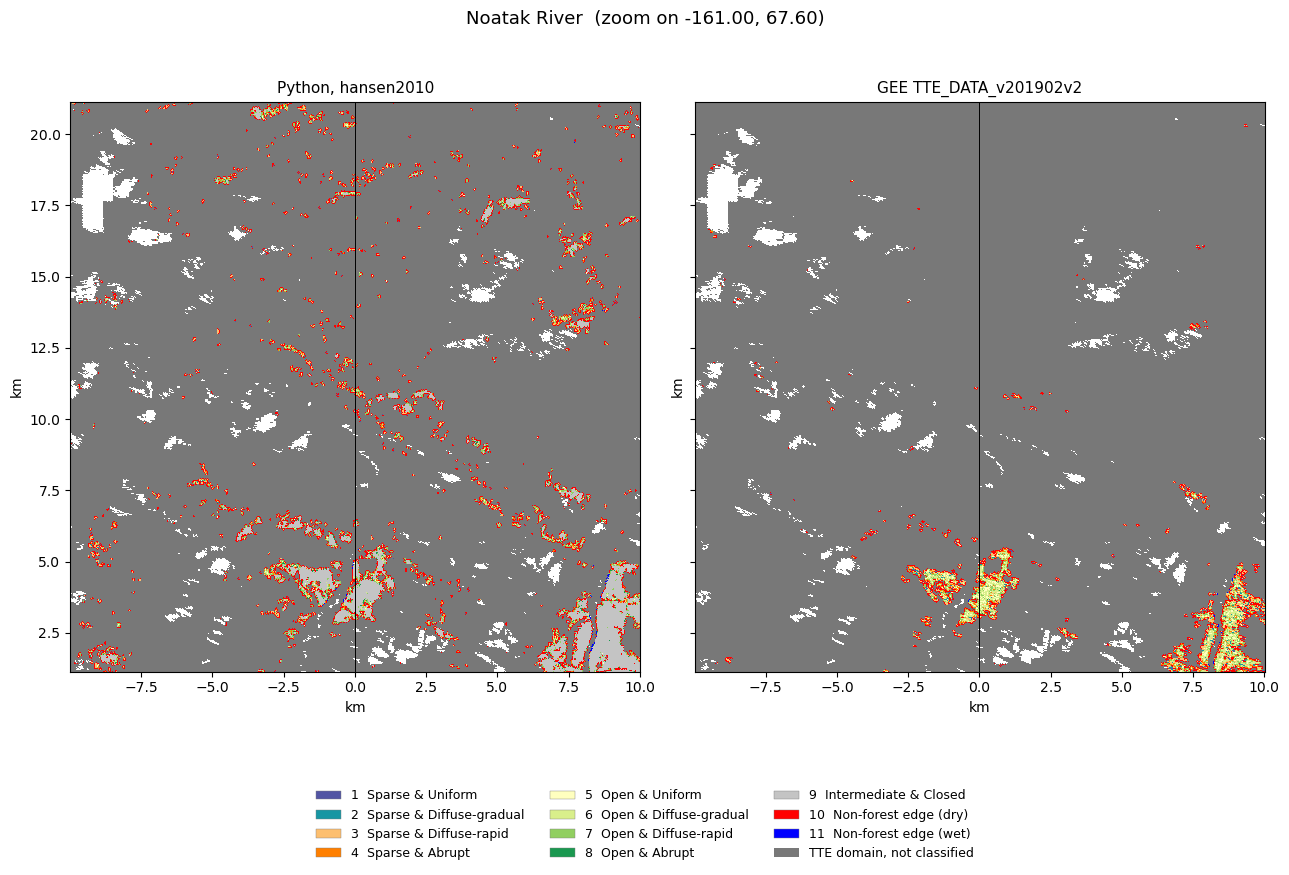

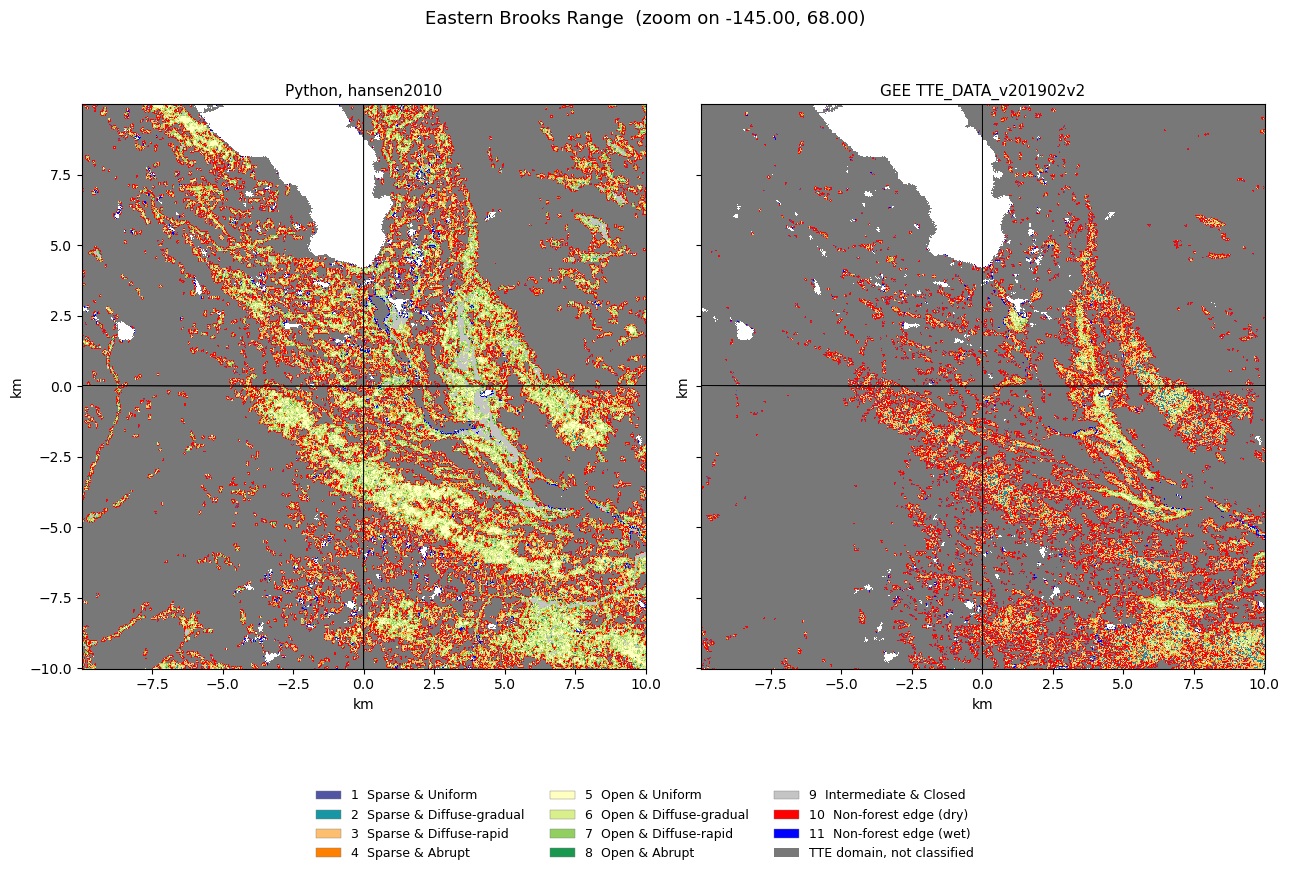

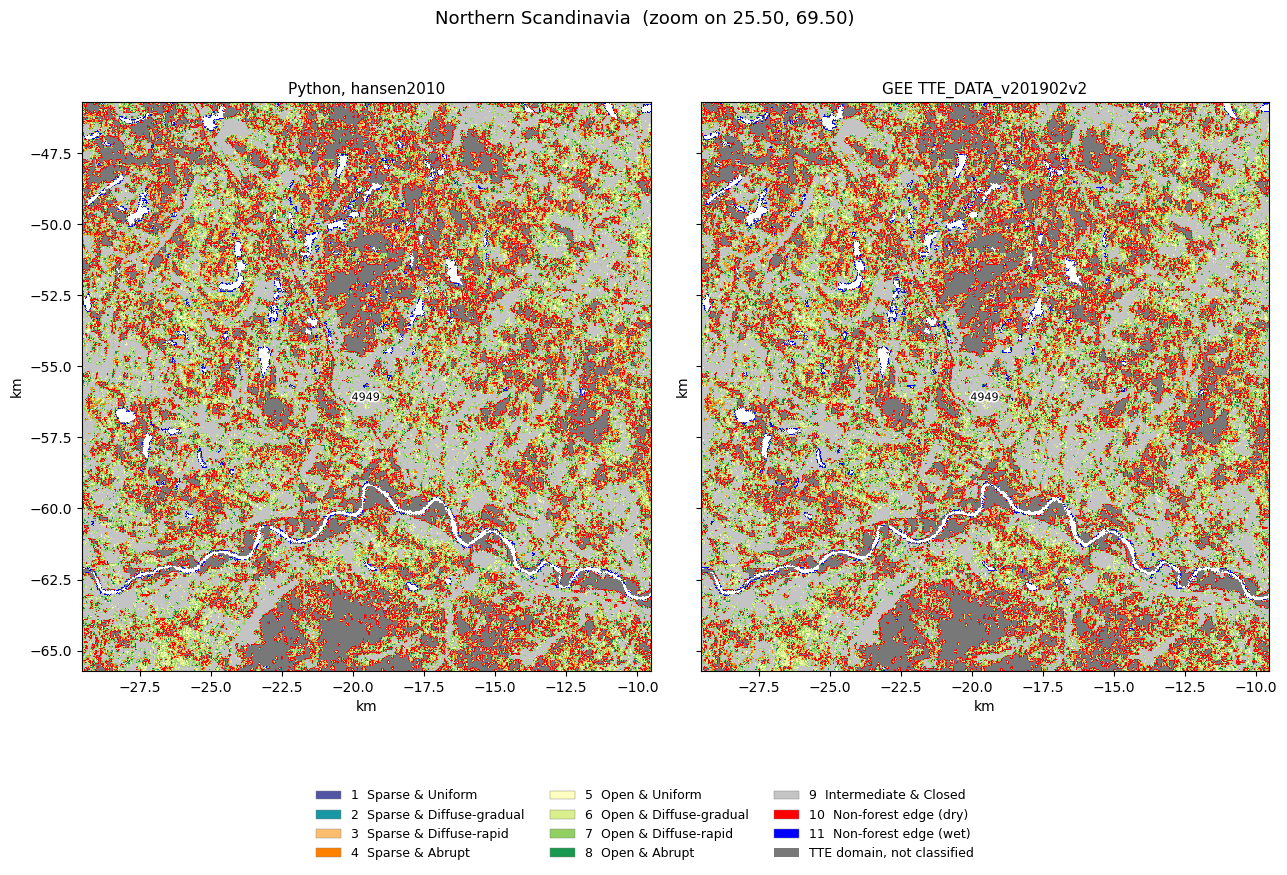

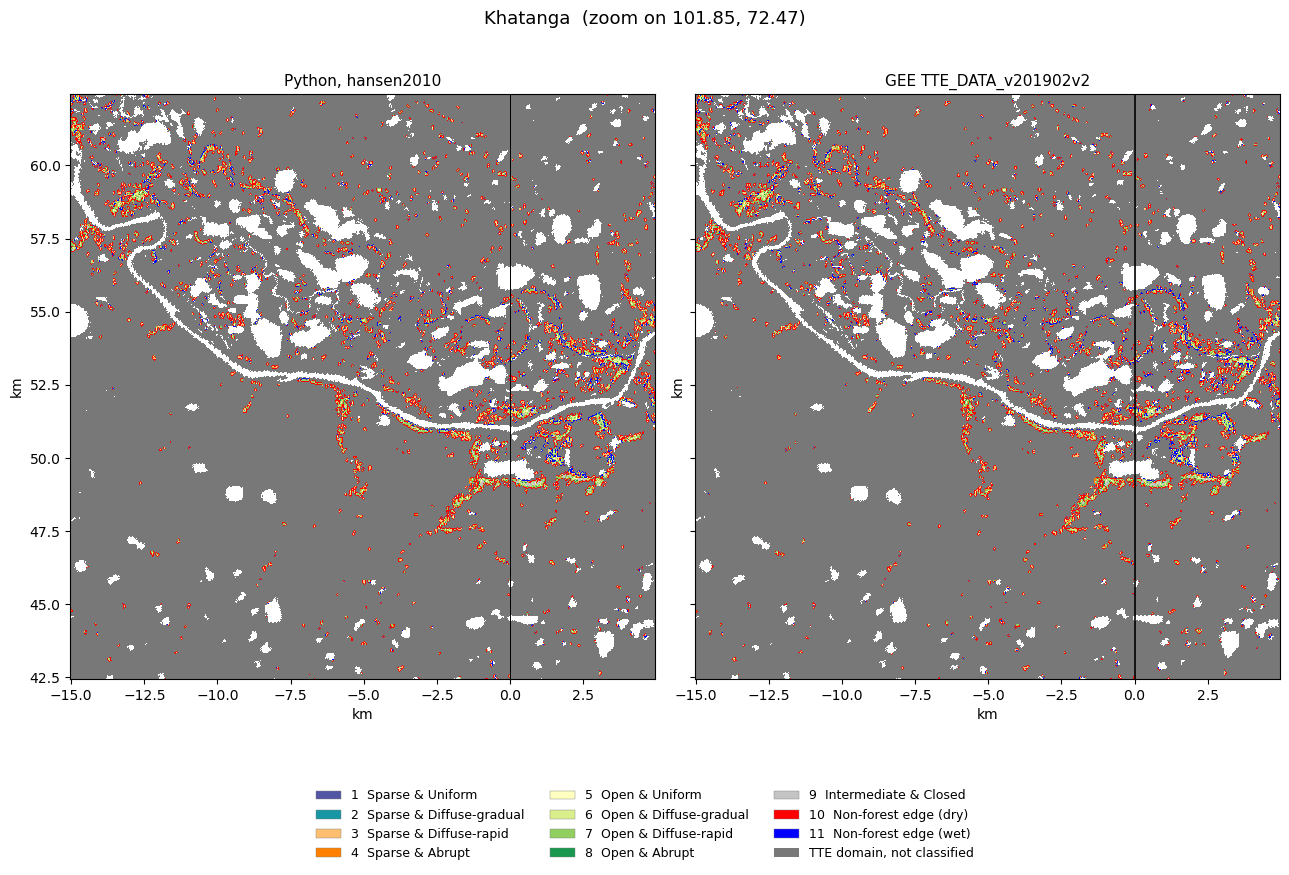

In [8]:
ZOOMS = {
    'Eastern Seward Peninsula': (-162.0, 65.0, 10),
    'Noatak River':             (-161.0, 67.6, 10),
    'Eastern Brooks Range':     (-145.0, 68.0, 10),
    'Northern Scandinavia':     (25.5, 69.5, 10),
    'Khatanga':                 (101.85, 72.47, 10),   # Ary-Mas
}
for name, z in ZOOMS.items():
    if name in DATA:
        show_site(name, zoom=z, figwidth=13)

## 7. Optional: the bands behind the classes

Tree cover (`tcc`, 0-50 % shown), abruptness (`tte_abruptness`, -1 uniform to 1 abrupt) and zones
(`tte_zones`: sparse, open, intermediate & closed) of the Python map, in the GEE palettes.

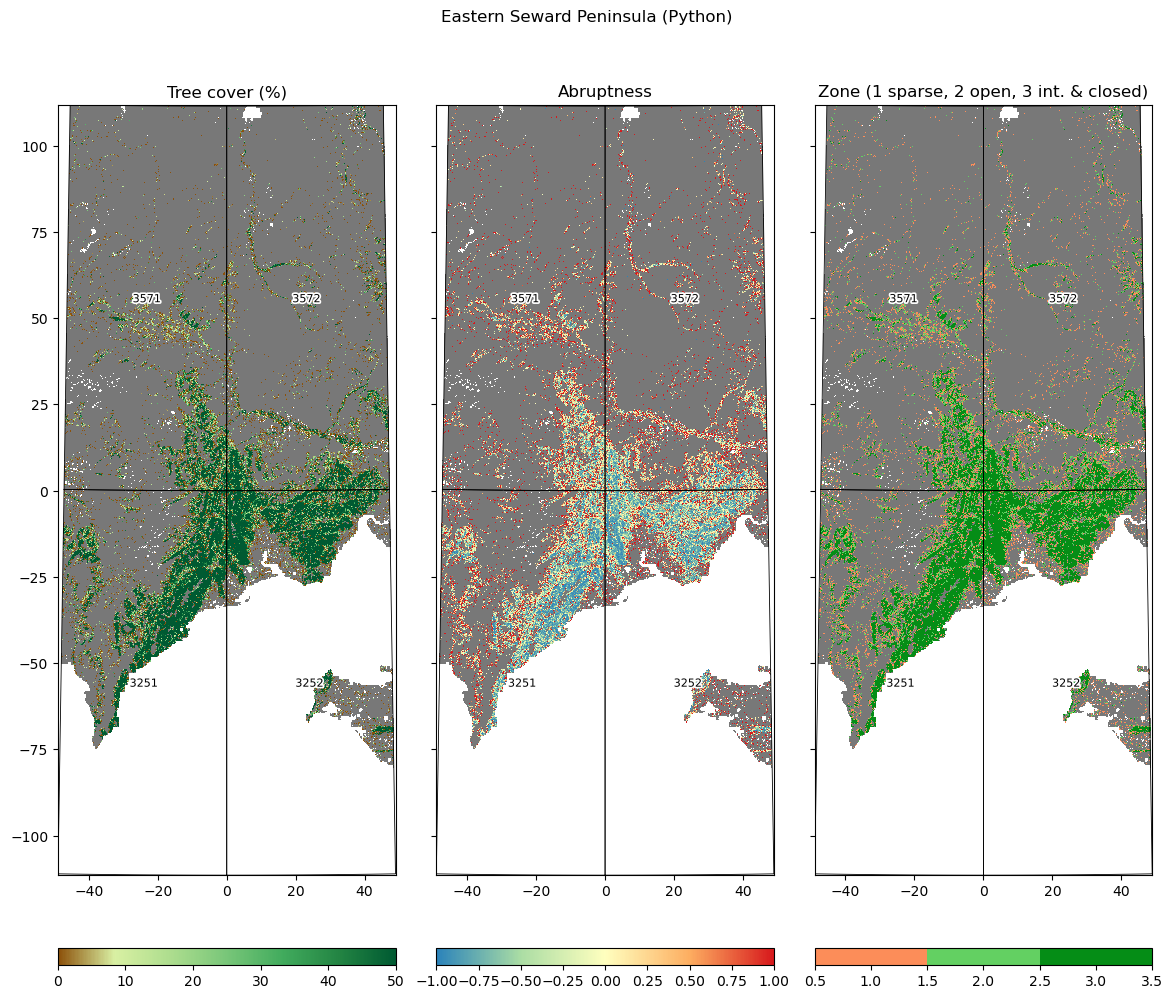

In [9]:
def show_bands(name, source='py', zoom=None, figwidth=16):
    d = DATA[name];  m = d[source];  grid = d['grid']
    specs = [('tcc', dict(cmap=TCC_CMAP, vmin=0, vmax=50), 'Tree cover (%)'),
             ('tte_abruptness', dict(cmap=ABR_CMAP, vmin=-1, vmax=1), 'Abruptness'),
             ('tte_zones', dict(cmap=ZONE_CMAP, vmin=0.5, vmax=3.5), 'Zone (1 sparse, 2 open, 3 int. & closed)')]
    W, H = fig_size(grid, 3, zoom, figwidth, max_panel_h=9, extra_h=1.2)
    fig, axes = plt.subplots(1, 3, figsize=(W, H), sharex=True, sharey=True)
    for ax, (b, kw, title) in zip(axes, specs):
        dom = np.where(np.isfinite(m['tte_domain']), 1.0, np.nan)
        ax.imshow(dom, extent=grid['extent'], cmap=ListedColormap([DOMAIN_COLOR]), interpolation='nearest')
        a = np.minimum(m[b], 3) if b == 'tte_zones' else m[b]       # GEE zone 4 (low rel. error) is closed too
        im = ax.imshow(a, extent=grid['extent'], interpolation='nearest', **kw)
        fig.colorbar(im, ax=ax, orientation='horizontal', fraction=0.05, pad=0.08)
        draw_tile_outlines(ax, d['tiles'], grid)
        ax.set_title(title)
    if zoom is not None:
        zoom_to(axes, grid, *zoom)
    fig.suptitle(f"{name} ({'Python' if source == 'py' else 'GEE'})")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / H))
    plt.show()

show_bands(list(DATA)[0])